# Работа 1 (28.09). Анализ датасета vgsales: пропуски, категориальные признаки, продажи игр

импорт библиотек

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

Загружаем датасет

In [4]:
df = pd.read_csv("vgsales.csv")

Общая информация о датасете

In [5]:
print("Количество строк:", df.shape[0])

Количество строк: 16598


In [6]:
print("Количество столбцов:", df.shape[1])

Количество столбцов: 11


In [7]:
print("\nНазвания столбцов:")
print(df.columns.tolist())


Названия столбцов:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']


In [8]:
print("\nТипы данных:")
print(df.dtypes)


Типы данных:
Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


In [9]:
print("\nСтатистические характеристики:")
df.describe()


Статистические характеристики:


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


Числовые столбцы: Rank, Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales

Текстовые столбцы: Name, Platform, Genre, Publisher

Столбцы с продажами: NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales

Количество пропусков в каждом столбце

In [11]:
print(df.isnull().sum())
print("\n- Строки, где отсутствует Year -")
df[df["Year"].isnull()]

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

- Строки, где отсутствует Year -


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,378,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,432,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
607,608,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53
...,...,...,...,...,...,...,...,...,...,...,...
16307,16310,Freaky Flyers,GC,NaN,Racing,Unknown,0.01,0.00,0.00,0.00,0.01
16327,16330,Inversion,PC,NaN,Shooter,Namco Bandai Games,0.01,0.00,0.00,0.00,0.01
16366,16369,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,Unknown,0.01,0.00,0.00,0.00,0.01
16427,16430,Virtua Quest,GC,NaN,Role-Playing,Unknown,0.01,0.00,0.00,0.00,0.01


Пропуски есть в столбцах Year и Publisher.

Больше всего пропусков в столбце Year (271 значение).

В Publisher — 58 пропусков.

Исходный размер

In [12]:
print("Строк в исходном датасете:", df.shape[0])

Строк в исходном датасете: 16598


Очищенный датасет

In [13]:
df_clean = df.dropna(subset=["Year"])

Размер после очистки

In [14]:
print("Строк после удаления пропусков Year:", df_clean.shape[0])
print("Пропусков в df_clean:")
print(df_clean.isnull().sum())

Строк после удаления пропусков Year: 16327
Пропусков в df_clean:
Rank             0
Name             0
Platform         0
Year             0
Genre            0
Publisher       36
NA_Sales         0
EU_Sales         0
JP_Sales         0
Other_Sales      0
Global_Sales     0
dtype: int64


В исходном датасете — 16 598 строк.

После удаления пропусков Year осталось — 16 327 строк.

Пропуски в Year мешают анализу, потому что нельзя группировать игры по годам, строить динамику продаж и т.д. — такие строки «выпадают» из временных рядов.

Изучение категориальных признаков

In [15]:
print("Жанры:", df_clean["Genre"].nunique())

Жанры: 12


In [16]:
print("Платформы:", df_clean["Platform"].nunique())

Платформы: 31


In [18]:
print("Издатели:", df_clean["Publisher"].nunique())

Издатели: 576


In [19]:
print("\nСписок жанров:")
print(df_clean["Genre"].unique())


Список жанров:
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']


Жанров — 12

Платформ — 31

Издателей — 578

Больше всего уникальных значений у признака Publisher.

Анализ жанров (количество игр)

In [20]:
genre_count = df_clean.groupby("Genre")["Name"].count().sort_values(ascending=False)
print(genre_count)

Genre
Action          3253
Sports          2304
Misc            1710
Role-Playing    1471
Shooter         1282
Adventure       1276
Racing          1226
Platform         876
Simulation       851
Fighting         836
Strategy         671
Puzzle           571
Name: Name, dtype: int64


Продажи по жанрам

In [21]:
genre_sales = df_clean.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)
print(genre_sales)

Genre
Action          1722.88
Sports          1309.24
Shooter         1026.20
Role-Playing     923.84
Platform         829.15
Misc             797.62
Racing           726.77
Fighting         444.05
Simulation       390.16
Puzzle           242.22
Adventure        234.80
Strategy         173.43
Name: Global_Sales, dtype: float64


Топ-10 игр по мировым продажам

In [22]:
top10 = df_clean.sort_values("Global_Sales", ascending=False).head(10)
top10[["Rank", "Name", "Platform", "Genre", "Global_Sales"]]

,Rank,Name,Platform,Genre,Global_Sales
0,1,Wii Sports,Wii,Sports,82.74
1,2,Super Mario Bros.,NES,Platform,40.24
2,3,Mario Kart Wii,Wii,Racing,35.82
3,4,Wii Sports Resort,Wii,Sports,33.00
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.37
5,6,Tetris,GB,Puzzle,30.26
6,7,New Super Mario Bros.,DS,Platform,30.01
7,8,Wii Play,Wii,Misc,29.02
8,9,New Super Mario Bros. Wii,Wii,Platform,28.62
9,10,Duck Hunt,NES,Shooter,28.31


Количество игр по платформам

In [23]:
platform_count = df_clean.groupby("Platform")["Name"].count().sort_values(ascending=False)

In [24]:
print("Топ-10 платформ по количеству игр:")
print(platform_count.head(10))


Топ-10 платформ по количеству игр:
Platform
DS      2133
PS2     2127
PS3     1304
Wii     1290
X360    1235
PSP     1197
PS      1189
PC       943
GBA      811
XB       803
Name: Name, dtype: int64


Суммарные продажи по платформам

In [25]:
platform_sales = df_clean.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False)

In [26]:
print("\nТоп-10 платформ по продажам:")
print(platform_sales.head(10))


Топ-10 платформ по продажам:
Platform
PS2     1233.46
X360     969.61
PS3      949.35
Wii      909.81
DS       818.96
PS       727.39
GBA      313.56
PSP      291.71
PS4      278.10
PC       255.05
Name: Global_Sales, dtype: float64


 Визуализация продаж по жанрам

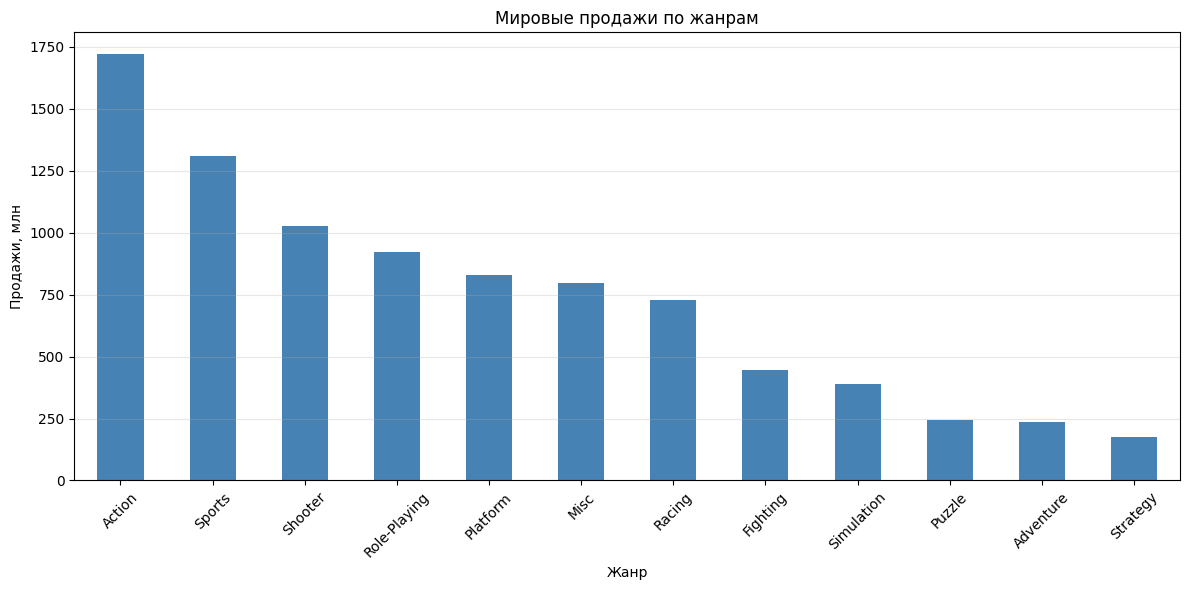

In [28]:
plt.figure(figsize=(12, 6))
genre_sales.sort_values(ascending=False).plot(kind="bar", color="steelblue")
plt.title("Мировые продажи по жанрам")
plt.xlabel("Жанр")
plt.ylabel("Продажи, млн")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Наибольшие продажи: Action, Sports, Shooter.

Наименьшие: Strategy, Puzzle.

Разница между лидером (Action ≈ 1 700 млн) и аутсайдером (Strategy ≈ 175 млн) — почти 10-кратная.

Корреляция NA_Sales и Global_Sales

In [29]:
corr_na_global = df_clean[["NA_Sales", "Global_Sales"]].corr()
print(corr_na_global)

              NA_Sales  Global_Sales
NA_Sales      1.000000      0.941268
Global_Sales  0.941268      1.000000


Значение положительное (~0.94).

Оно близко к 1.

Да, можно говорить о выраженной положительной взаимосвязи: чем больше продажи в Северной Америке, тем выше мировые продажи.

 Диаграмма рассеяния

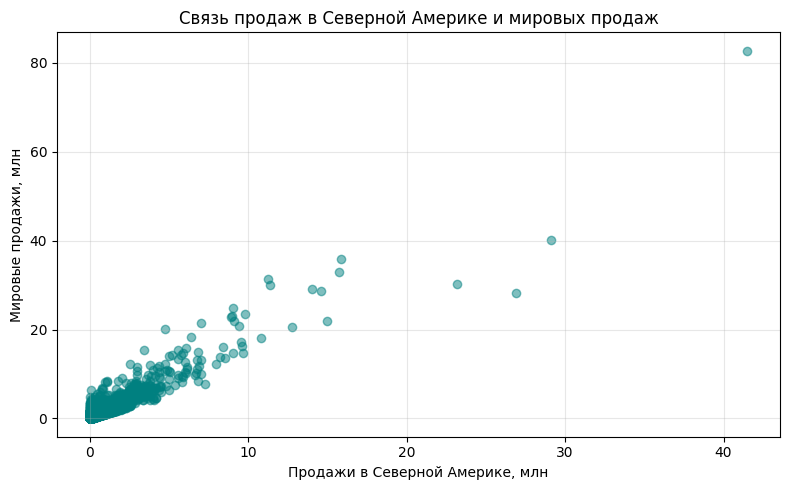

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean["NA_Sales"],
    df_clean["Global_Sales"],
    alpha=0.5,
    color="teal"
)
plt.title("Связь продаж в Северной Америке и мировых продаж")
plt.xlabel("Продажи в Северной Америке, млн")
plt.ylabel("Мировые продажи, млн")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Одна точка — одна игра из датасета.

Да, наблюдается восходящая тенденция (при росте NA_Sales растут и Global_Sales).

График соответствует результату корреляционного анализа.

 Корреляция между регионами

In [31]:
region_corr = df_clean[
    ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
].corr()
print(region_corr)

              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales      1.000000  0.768936  0.451285     0.634508      0.941268
EU_Sales      0.768936  1.000000  0.436414     0.726266      0.903271
JP_Sales      0.451285  0.436414  1.000000     0.290653      0.612794
Other_Sales   0.634508  0.726266  0.290653     1.000000      0.747974
Global_Sales  0.941268  0.903271  0.612794     0.747974      1.000000


Тепловая карта

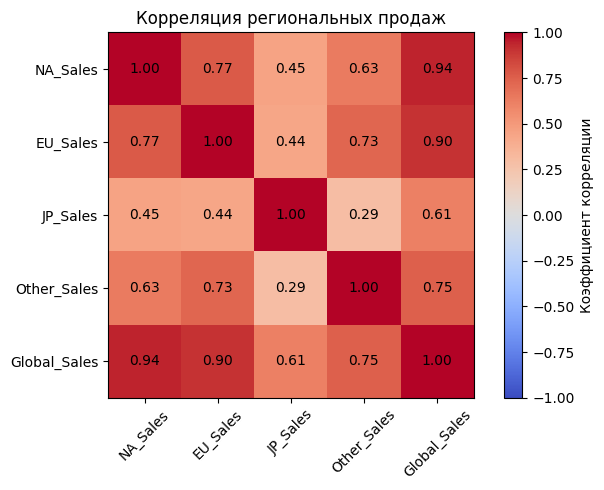

In [32]:
plt.figure(figsize=(7, 5))
plt.imshow(region_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Коэффициент корреляции")
plt.xticks(range(len(region_corr)), region_corr.columns, rotation=45)
plt.yticks(range(len(region_corr)), region_corr.columns)
for i in range(len(region_corr)):
    for j in range(len(region_corr)):
        plt.text(j, i, f"{region_corr.iloc[i, j]:.2f}",
                 ha="center", va="center", color="black")
plt.title("Корреляция региональных продаж")
plt.tight_layout()
plt.show()

# Работа 2 (12.10). Titanic: признаки, пропуски, корреляция и тепловая карта

импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Настройки отображения

In [2]:
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

файл

In [3]:
df = pd.read_csv('titanic.csv')

Выбор признаков и целевой переменной

In [4]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

In [5]:
data = df[features + [target]].copy()
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,male,7.2500,1,0,0
1,1,38.0,female,71.2833,1,0,1
2,3,26.0,female,7.9250,0,0,1
3,1,35.0,female,53.1000,1,0,1
4,3,35.0,male,8.0500,0,0,0


Проверка пропущенных значений

In [6]:
data.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


Заполняем пропуски медианой

In [7]:
data['Age'] = data['Age'].fillna(data['Age'].median())

Проверяем результат

In [8]:
data.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


Преобразование Sex в числовой вид

In [9]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [10]:
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


Проверка типов и пропусков

In [11]:
print("Типы данных:")
print(data.dtypes)
print("\nПропущенные значения:")
print(data.isnull().sum())
print("\nРазмер таблицы:", data.shape)

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропущенные значения:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64

Размер таблицы: (891, 7)


Расчёт корреляционной матрицы

In [12]:
corr_matrix = data.corr()

Округление до 2 знаков

In [13]:
corr_matrix_rounded = corr_matrix.round(2)
corr_matrix_rounded

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


Столбец Survived без самой себя

In [14]:
survived_corr = corr_matrix['Survived'].drop('Survived').sort_values(ascending=False)

In [15]:
print("Корреляция признаков с Survived:")
print(survived_corr)

Корреляция признаков с Survived:
Sex       0.543351
Fare      0.257307
Parch     0.081629
SibSp    -0.035322
Age      -0.064910
Pclass   -0.338481
Name: Survived, dtype: float64


In [16]:
print("\nНаиболее сильная положительная корреляция:")
print(survived_corr.idxmax(), "=", round(survived_corr.max(), 2))



Наиболее сильная положительная корреляция:
Sex = 0.54


In [17]:
print("\nНаиболее сильная отрицательная корреляция:")
print(survived_corr.idxmin(), "=", round(survived_corr.min(), 2))


Наиболее сильная отрицательная корреляция:
Pclass = -0.34


In [18]:
plt.figure(figsize=(10, 8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

 Построение тепловой карты

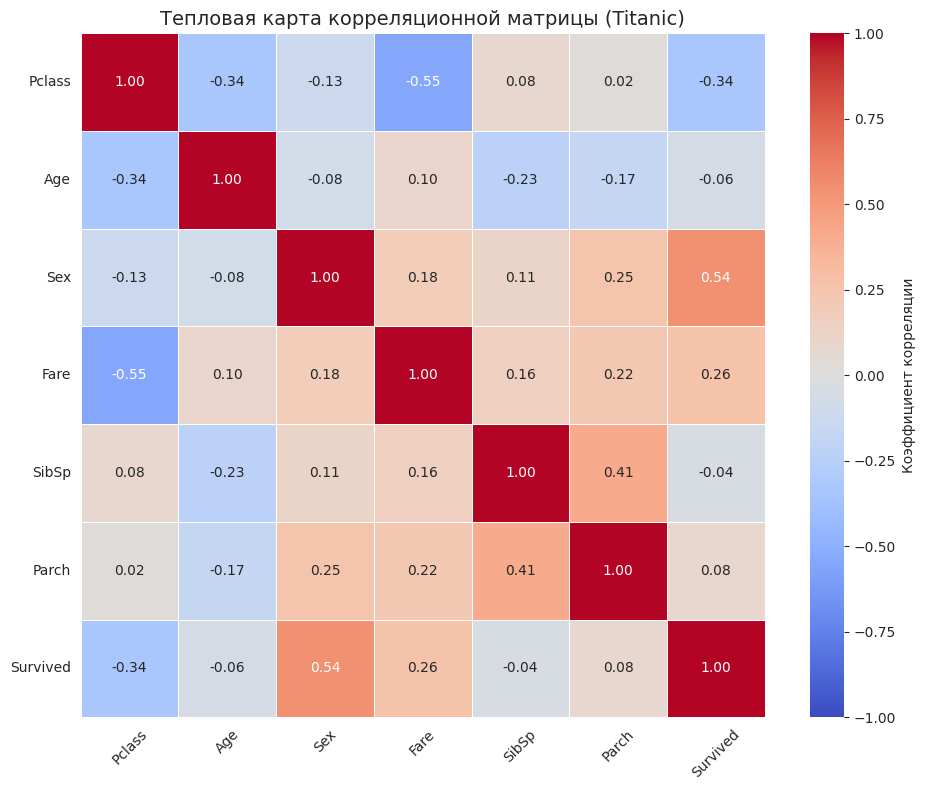

In [19]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1, vmax=1,
    square=True,
    cbar_kws={'label': 'Коэффициент корреляции'}
)

plt.title('Тепловая карта корреляционной матрицы (Titanic)', fontsize=14)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Работа 3. Titanic: обучающая и тестовая выборки, обучение моделей и метрики

импорт библиотек

In [41]:
import pandas as pd
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

файл

In [42]:
df = pd.read_csv("titanic.csv")

Выбираем признаки и целевую переменную

In [44]:
features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

Кодируем категориальный признак Sex

In [45]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

Заполняем медианой только числовые колонки

In [46]:
X = X.fillna(X.median())

Проверка, что пропусков больше нет

In [47]:
print("Пропуски в данных:\n", X.isnull().sum())

Пропуски в данных:
 Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64


Разделение на train/test

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Масштабирование

In [49]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [50]:
print("Размер X_train:", X_train.shape)
print("Размер X_test: ", X_test.shape)

Размер X_train: (712, 6)
Размер X_test:  (179, 6)


Теперь ошибки не будет, так как в X_train_scaled нет NaN

In [51]:
model_lr = LogisticRegression(max_iter=1000)

In [52]:
model_lr.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000)

In [53]:
y_pred_lr = model_lr.predict(X_test_scaled)

In [54]:
print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:  ", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы:   [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


In [55]:
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1-score :", f1_score(y_test, y_pred_lr))
print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy : 0.8044692737430168
Precision: 0.765625
Recall   : 0.7101449275362319
F1-score : 0.7368421052631579

Матрица ошибок:
[[95 15]
 [20 49]]


In [56]:
model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)

Дереву масштабирование не нужно, подаем обычный X_train

In [57]:
model_tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [58]:
y_pred_tree = model_tree.predict(X_test)

In [59]:
print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision       :", precision_score(y_test, y_pred_tree))
print("Recall          :", recall_score(y_test, y_pred_tree))
print("F1-score        :", f1_score(y_test, y_pred_tree))


Accuracy дерева: 0.7821229050279329
Precision       : 0.875
Recall          : 0.5072463768115942
F1-score        : 0.6422018348623854


Считаем корреляцию для числовых признаков + Survived + Sex

In [60]:
corr_df = df[["Survived", "Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
corr_df["Sex"] = corr_df["Sex"].map({"male": 0, "female": 1})

Выводим корреляцию с целевой переменной, сортируя по убыванию

In [61]:
correlation = corr_df.corr()["Survived"].sort_values(ascending=False)
print("Корреляция признаков с Survived:\n")
print(correlation)

Корреляция признаков с Survived:

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64


# Термины к зачёту

**Признаки (features)** — входные столбцы таблицы, по которым модель делает предсказание. В работах 2 и 3 это `Pclass, Age, Sex, Fare, SibSp, Parch`. То, что предсказываем (`Survived`), называется целевой переменной.

**Обучающая выборка** — часть данных, на которой модель учится (`X_train`, `y_train`). Остальные данные — тестовая выборка, на ней проверяют качество. В работе 3 разбиение 80/20: `train_test_split(test_size=0.2)`.

**Пропуски** — отсутствующие значения (NaN). Находим через `df.isnull().sum()`. Их либо удаляют (`dropna`, работа 1), либо заполняют, например медианой (`fillna`, работы 2 и 3).

**Корреляция** — число от −1 до 1, показывает, насколько сильно связаны два признака. Близко к 1 — растут вместе, близко к −1 — один растёт, другой падает, около 0 — связи нет. Считается через `df.corr()`.

**Машинное обучение** — подход, при котором компьютер сам находит закономерности в данных и потом использует их для предсказаний, а не работает по правилам, которые написал человек.

**Тепловая карта (heatmap)** — цветная таблица, в которой цвет показывает значение. Обычно так рисуют матрицу корреляций (`sns.heatmap(..., annot=True)`, работа 2).

**Обучение модели** — подбор параметров модели по обучающей выборке: `model.fit(X_train, y_train)`. После этого модель делает предсказания (`predict`), и качество оценивают по метрикам: accuracy, precision, recall, F1 (работа 3).
